---
---

<h1><center><ins>Exercise Sheet 3</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp

## Exercise 1 - Root finding algorithms

**(A)** Implement the *bisection*, *secant*, *false position* and *Newton-Raphson* root finding methods, by coding your own version of these algorithms. Make sure to test your codes, checking that indeed they are able to find the root of a function (to do this, you can for example pick an analytic function that allows you to test the codes and for which you can compute the roots analytically).

**(B)** Use your implementation of the 4 root finding methods (from part **A**) to compute the root of the function:

$$f(x) = e^x - 1 - x - \frac{x^2}{2}$$

in the interval $x\in[-1,2]$. For each method, print out the position of the root and the number of iterations needed to reach it.

**(C)** Discuss your results, commenting how the methods compare to one another. Which one is the fastest/slowest? Why? What is the impact of the points you selected to start your iterations?

In [27]:
def f(x):
    return np.exp(x) - 1 - x - x**2 / 2

def df(x):
    return np.exp(x) - 1 - x


# Bisection method
def bisection(f, a, b, tol=1e-10, max_iter=1000):
    if f(a) * f(b) > 0:
        raise ValueError("Secant denominator is too small.")

    for i in range(1, max_iter + 1):
        c = (a + b) / 2

        if abs(f(c)) < tol or abs(b - a) / 2 < tol:
            return c, i

        if f(a) * f(c) < 0:
            b = c
        else:
            a = c

    return c, max_iter


# Secant method
def secant(f, x0, x1, tol=1e-10, max_iter=1000):
    for i in range(1, max_iter + 1):
        f0 = f(x0)
        f1 = f(x1)

        if abs(f1) < tol:
            return x1, i - 1

        if f1 == f0:
            raise ZeroDivisionError("secant slope is zero")

        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        f2 = f(x2)
        
        if abs(x2 - x1) < tol:
            return x2, i

        x0, f0 = x1, f1
        x1, f1 = x2, f2

    return x1, max_iter


# False Position
def false_position(f, a, b, tol=1e-10, max_iter=1000):
    if f(a) * f(b) > 0:
        raise ValueError("f(a) and f(b) must have opposite signs.")

    for i in range(1, max_iter + 1):
        fa, fb = f(a), f(b)
        c = b - fb * (b - a) / (fb - fa)
        fc = f(c)

        if abs(fc) < tol or abs(b - a) < tol:
            return c, i

        if fa * fc < 0:
            b = c
        else:
            a = c

    return c, max_iter


# Newton-Raphson method
def newton_raphson(f, df, x0, tol=1e-10, max_iter=1000):
    x = x0

    for i in range(1, max_iter + 1):
        fx = f(x)
        dfx = df(x)

        if abs(fx) < tol:
            return x, i - 1

        if abs(dfx) < 1e-15:
            raise ValueError("Derivative is too small.")

        x_new = x - fx / dfx

        if abs(x_new - x) < tol:
            return x_new, i

        x = x_new

    return x, max_iter




In [28]:

# Initial values
a, b = -1.0, 2.0

methods = [
    ("Bisection", lambda: bisection(f, a, b)),
    ("Secant", lambda: secant(f, -1.0, 2.0)),
    ("False Position", lambda: false_position(f, a, b)),
    ("Newton-Raphson", lambda: newton_raphson(f, df, 2.0)),
]

for name, method in methods:
    try:
        root, iterations = method()
        print(f"{name:16s}: root = {root:.12e}, "
              f"iterations = {iterations}, ")
    except (ValueError, ZeroDivisionError) as error:
        print(f"{name:16s}: failed - {error}")


Bisection       : root = 4.882812500000e-04, iterations = 11, 
Secant          : root = -7.617644095643e-04, iterations = 26, 
False Position  : root = -5.887471723992e-02, iterations = 1000, 
Newton-Raphson  : root = 8.047886646472e-04, iterations = 20, 


Bisectioin is the fastest because it halfes the interval every time leading to quickly finding out the root and false position took the longest because one endpoint changed very little.
The points i select to start can influence how quickly a method approaches the root and you have to consider that bisection and false postion need points with opposite sings.

## Exercise 2 - Sets of linear equations

Determine the solution to the following set of linear equations:

$$ 
\begin{cases}
5 x_1 + 3 x_2 &= 15 \\
x_1 - 4 x_2 &= -2 \ ,
\end{cases}
$$

where $x_1$ and $x_2$ are the variables of interest.

**(A)** Formulate the problem by using the matrix representation, as we saw in class, clearly defining the coefficient matrix and the vector of right-hand-side values.

**(B)** Using the appropriate built-in python functions, carry out the LU decomposition of the coefficient matrix, and print out the L and U matrices separately. Solve the set of equations and check that the solution is indeed valid.

**(C)** What is the solution to the following set of equations? 

$$ 
\begin{cases}
x_1 - 4 x_2 &= 3 \\
5 x_1 + 3 x_2 &= -7
\end{cases}
$$

Print out the solution, and motivate the steps you took to solve it.

In [29]:
A = np.array([
    [5, 3],
    [1, -4]
], dtype=float)

b = np.array([15, -2], dtype=float)

print("Coefficient matrix A:")
print(A)

print("Right-hand-side vector b:")
print(b)


Coefficient matrix A:
[[ 5.  3.]
 [ 1. -4.]]
Right-hand-side vector b:
[15. -2.]


In [30]:
from scipy.linalg import lu, lu_factor, lu_solve

P, L, U = lu(A)

print("L matrix:")
print(L)

print("U matrix:")
print(U)

print("P matrix:")
print(P)

lu_data = lu_factor(A)
x = lu_solve(lu_data, b)

print("Solution:")
print(x)

print("A @ x:")
print(A @ x)

print("Right-hand side b:")
print(b)

print("Check:", np.allclose(A @ x, b))

L matrix:
[[1.  0. ]
 [0.2 1. ]]
U matrix:
[[ 5.   3. ]
 [ 0.  -4.6]]
P matrix:
[[1. 0.]
 [0. 1.]]
Solution:
[2.34782609 1.08695652]
A @ x:
[15. -2.]
Right-hand side b:
[15. -2.]
Check: True


In [31]:
A2 = np.array([
    [1, -4],
    [5,  3]
], dtype=float)

b2 = np.array([3, -7], dtype=float)

x2 = np.linalg.solve(A2, b2)

print("Solution:")
print("x1 =", x2[0])
print("x2 =", x2[1])

print("A2 @ x2 =", A2 @ x2)
print("b2 =", b2)
print("Check:", np.allclose(A2 @ x2, b2))


Solution:
x1 = -0.826086956521739
x2 = -0.9565217391304349
A2 @ x2 = [ 3. -7.]
b2 = [ 3. -7.]
Check: True


## Exercise 3 - The Newton fractal

In the lecture, we discussed the Newton fractal. The aim of this exercise is to plot it. 

**(A)** Generate a complex plane of numbers between [-2,2] for the real and imaginary parts. You can use the function np.linspace for the Re and Im parts (assume a sufficient number of points, for instance, a few hundred), and then use np.meshgrid to create a full Re, Im grid. You create the complex numbers by using Z = X + 1j * Y. This is the initial set of complex points for your iteration.

**(B)** For every starting point in your grid that you generated in (A), run the Newton-Raphson iteration as $$z_{i+1} = z_{i} - \frac{z_{i}^3 - 1}{3 z_{n}^2} $$ Test how many times you need to run the iteration for the values to converge to one of the three roots (tip: several tens of iteration should be sufficient).

**(C)** Calculate analytically or look up online the three roots of the function $$f(z) = z^3 - 1$$ and store them. For each point you have obtained in (B), calculate the distance to every root using, for instance, np.abs. and determine the nearest root. 

**(D)** Plot the result. You can use the function plt.imshow or a similar solution. Assign the color to each plot according to the nearest root. Add the three roots using e.g. plt.scatter.

In [39]:
re = np.linspace(-2, 2, 2000)
im = np.linspace(-2, 2, 2000)

X, Y = np.meshgrid(re, im)

Z = X + 1j * Y

In [33]:

z = Z.copy()

max_iter = 50
tol = 1e-8

iterations = np.zeros(Z.shape, dtype=int)

active = np.ones(Z.shape, dtype=bool)

for n in range(1, max_iter + 1):

    valid = active & (np.abs(z) > 1e-14)

    z[valid] = z[valid] - (
        z[valid]**3 - 1
    ) / (3 * z[valid]**2)

    converged = active & (np.abs(z**3 - 1) < tol)

    iterations[converged] = n

    active[converged] = False

iterations[active] = max_iter + 1

print("Number of grid points:", Z.size)
print("Converged points:", np.sum(~active))
print("Not converged:", np.sum(active))


Number of grid points: 4000000
Converged points: 3999998
Not converged: 2


In [45]:
roots = np.exp(2j * np.pi * np.arange(3) / 3)

print("The three roots are:")
for root in roots:
    print(root)


The three roots are:
(1+0j)
(-0.4999999999999998+0.8660254037844387j)
(-0.5000000000000004-0.8660254037844385j)


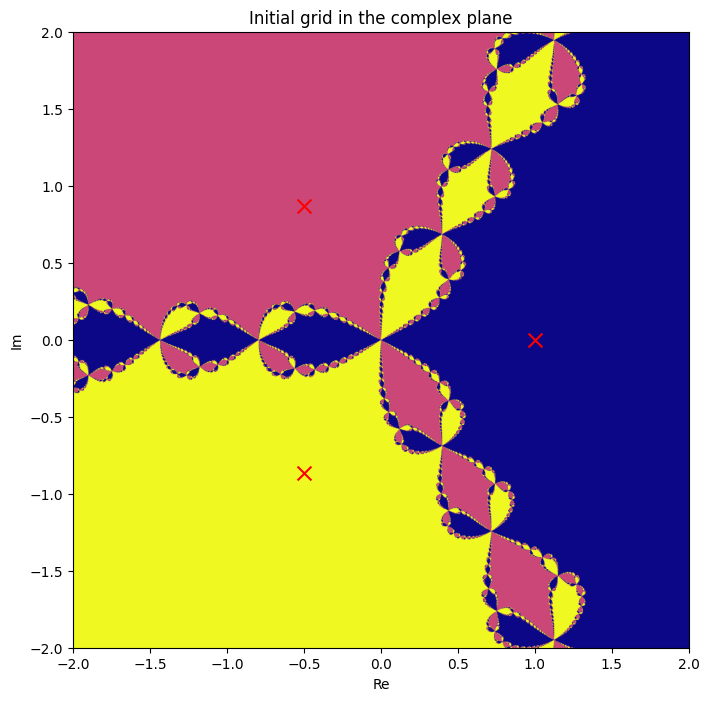

In [46]:
plt.figure(figsize=(8, 8))
plt.imshow(
    np.ma.masked_equal(nearest_root, -1),
    extent=[-2, 2, -2, 2],
    origin="lower",
    cmap="plasma",
    vmin=0,
    vmax=2
)
plt.scatter(roots.real, roots.imag, color="red", marker="x", s=100)
plt.xlabel("Re")
plt.ylabel("Im")
plt.title("Initial grid in the complex plane")
plt.show()